# Prédiction du prix de l'immobilier

**Objectif :** prédire le prix de vente d'une maison (`SalePrice`) à partir de ses caractéristiques.
**Métrique :** MAE (erreur absolue moyenne), en dollars.

## 0. Imports

In [53]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import KFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

from src.preprocessing import preparer_donnees

# Cache une fausse alerte de numpy sur Mac (sans effet sur les résultats)
warnings.filterwarnings("ignore", message=".*encountered in matmul")

In [54]:
train = pd.read_csv("data/raw/kaggle_train_set.csv")
train.head()

,OverallQual,GrLivArea,TotalBsmtSF,1stFlrSF,YearBuilt,YearRemodAdd,GarageCars,GarageArea,FullBath,TotRmsAbvGrd,KitchenQual,Fireplaces,LotArea,Neighborhood,ExterQual,SalePrice
0,7,1710,856,856,2003,2003,2,548,2,8,Gd,0,8450,CollgCr,Gd,208500
1,6,1262,1262,1262,1976,1976,2,460,2,6,TA,1,9600,Veenker,TA,181500
2,7,1786,920,920,2001,2002,2,608,2,6,Gd,1,11250,CollgCr,Gd,223500
3,8,1694,1686,1694,2004,2005,2,636,2,7,Gd,1,10084,Somerst,Gd,307000
4,7,1774,952,1022,1931,1950,2,468,2,8,TA,2,6120,OldTown,TA,129900


In [55]:
print("Nombre de maisons :", train.shape[0])
print("Nombre de colonnes :", train.shape[1])
print("Valeurs manquantes :", train.isna().sum().sum())

Nombre de maisons : 1180
Nombre de colonnes : 16
Valeurs manquantes : 0


In [56]:
from sklearn.model_selection import train_test_split

X = train.drop(columns="SalePrice")
y = train["SalePrice"]

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Entraînement :", X_train.shape)
print("Validation :", X_val.shape)

Entraînement : (944, 15)
Validation : (236, 15)


## 2. Découpage entraînement / validation

Je mets 20 % des maisons de côté pour la validation **avant** d'explorer le prix,
pour ne pas m'inspirer des maisons qui serviront à évaluer le modèle.

In [57]:
X = train.drop(columns="SalePrice")
y = train["SalePrice"]

# 80 % pour l'entraînement, 20 % pour la validation
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

print("Entraînement :", X_train.shape)
print("Validation :", X_val.shape)

Entraînement : (944, 15)
Validation : (236, 15)


## 3. Distribution du prix de vente

In [58]:
display(y_train.describe().round(0))

log_prix = np.log(y_train)

# Asymétrie : 0 = symétrique, > 1 = longue queue vers les prix élevés
print(f"Asymétrie du prix : {y_train.skew():.2f}")
print(f"Asymétrie du logarithme du prix : {log_prix.skew():.2f}")

count       944.0
mean     180158.0
std       79876.0
min       34900.0
25%      129000.0
50%      162000.0
75%      212000.0
max      755000.0
Name: SalePrice, dtype: float64

Asymétrie du prix : 1.78
Asymétrie du logarithme du prix : 0.07


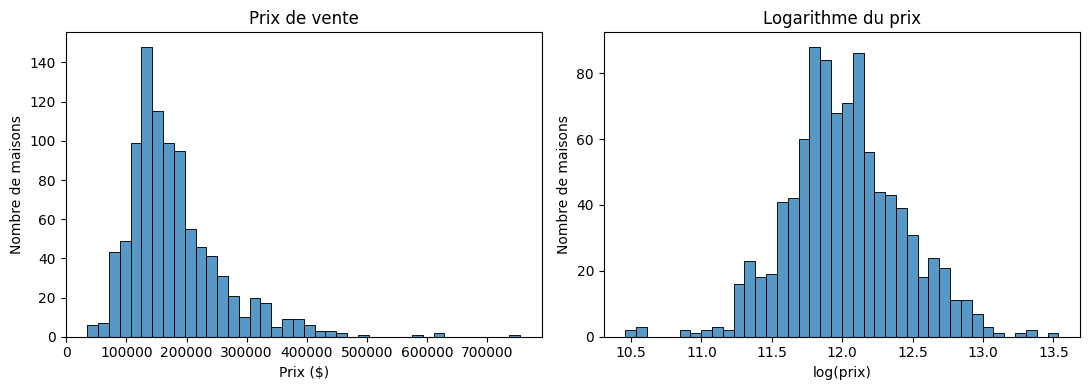

In [59]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

sns.histplot(x=y_train, bins=40, ax=axes[0])
axes[0].set(title="Prix de vente", xlabel="Prix ($)", ylabel="Nombre de maisons")

sns.histplot(x=log_prix, bins=40, ax=axes[1])
axes[1].set(title="Logarithme du prix", xlabel="log(prix)", ylabel="Nombre de maisons")

plt.tight_layout()
plt.show()

La plupart des maisons se vendent entre 129 000 \$ et 212 000 \$ (prix médian : 162 000 \$),
mais quelques maisons très chères tirent la distribution vers la droite (asymétrie de 1,78).
En passant au logarithme, la distribution devient presque symétrique (0,07) :
je testerai plus loin si entraîner les modèles sur log(prix) améliore les résultats.

In [60]:
colonnes_numeriques = X_train.select_dtypes(include="number").columns.tolist()
colonnes_categorielles = X_train.select_dtypes(exclude="number").columns.tolist()

print("Colonnes numériques :", colonnes_numeriques)
print("Colonnes catégorielles :", colonnes_categorielles)

Colonnes numériques : ['OverallQual', 'GrLivArea', 'TotalBsmtSF', '1stFlrSF', 'YearBuilt', 'YearRemodAdd', 'GarageCars', 'GarageArea', 'FullBath', 'TotRmsAbvGrd', 'Fireplaces', 'LotArea']
Colonnes catégorielles : ['KitchenQual', 'Neighborhood', 'ExterQual']


In [61]:
pretraitement = ColumnTransformer([
    # Nombres : mis à la même échelle (moyenne 0, écart-type 1)
    ("numerique", StandardScaler(), colonnes_numeriques),
    # Texte : une colonne 0/1 par catégorie
    ("categoriel", OneHotEncoder(handle_unknown="ignore"), colonnes_categorielles),
])

## 5. Premier modèle : régression Ridge

Ridge est une régression linéaire avec une pénalité qui évite que les coefficients deviennent trop grands.
Le `Pipeline` enchaîne la préparation des variables et le modèle.

In [62]:


modele_ridge = Pipeline([
    ("pretraitement", pretraitement),
    ("regression", Ridge(alpha=1.0)),
])

modele_ridge.fit(X_train, y_train)

,steps,"[('pretraitement', ...), ('regression', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('numerique', ...), ('categoriel', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


### Comparaison avec une référence naïve

Pour savoir si le modèle est utile, je le compare à une méthode très simple :
prédire le prix médian pour toutes les maisons.

In [63]:
# Référence : on prédit le prix médian pour toutes les maisons
prix_median = y_train.median()
mae_reference = mean_absolute_error(y_val, [prix_median] * len(y_val))

predictions_ridge = modele_ridge.predict(X_val)
mae_ridge = mean_absolute_error(y_val, predictions_ridge)

print(f"MAE de la référence : {mae_reference:,.0f} $")
print(f"MAE de Ridge        : {mae_ridge:,.0f} $")

MAE de la référence : 54,691 $
MAE de Ridge        : 20,937 $


### Premiers résultats

Le modèle Ridge a été entraîné sur 944 maisons et évalué sur les 236 maisons de validation.

| Méthode | MAE |
|---|---:|
| Référence (prix médian) | 54 691 \$ |
| Régression Ridge | 20 937 \$ |

Ridge divise l'erreur par plus de 2,5 par rapport à la référence (−62 %) : le modèle apprend bien quelque chose.

## 6. Analyse des plus grosses erreurs

Je regarde les 5 maisons pour lesquelles Ridge se trompe le plus.

In [64]:
erreurs = X_val[["OverallQual", "GrLivArea", "Neighborhood"]].copy()
erreurs["prix_reel"] = y_val
erreurs["prix_predit"] = predictions_ridge.round().astype(int)
erreurs["erreur"] = (erreurs["prix_predit"] - erreurs["prix_reel"]).abs()

display(erreurs.nlargest(5, "erreur"))

,OverallQual,GrLivArea,Neighborhood,prix_reel,prix_predit,erreur
1047,10,5642,Edwards,160000,670004,510004
141,10,3608,OldTown,475000,341647,133353
382,8,1976,NridgHt,440000,308306,131694
355,10,2402,NridgHt,555000,441099,113901
545,6,2380,NAmes,129000,212073,83073


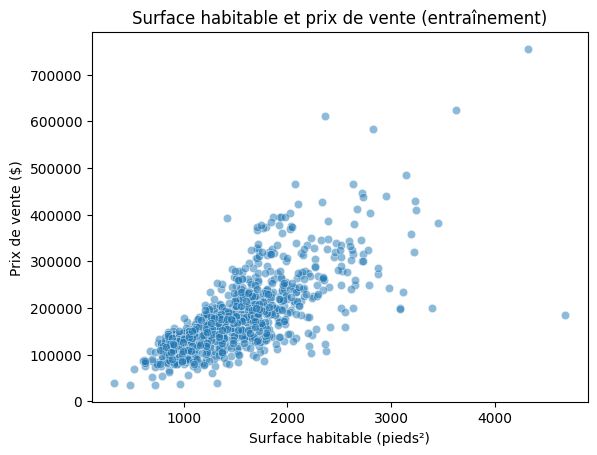

In [65]:
sns.scatterplot(x=X_train["GrLivArea"], y=y_train, alpha=0.5)
plt.title("Surface habitable et prix de vente (entraînement)")
plt.xlabel("Surface habitable (pieds²)")
plt.ylabel("Prix de vente ($)")
plt.show()

La pire erreur concerne la maison 1047 : 5 642 pieds², qualité 10, vendue seulement 160 000 \$,
alors que Ridge prédit 670 000 \$. Elle est plus grande que toutes les maisons d'entraînement
(maximum : 4 676 pieds²).

Sur le graphique, on voit une maison du même type dans l'entraînement, en bas à droite :
la maison 421 (4 676 pieds², quartier Edwards, 184 750 \$). Ces maisons immenses mais bon marché
ne suivent pas la tendance générale. Je reviendrai sur leur cas à la fin.

## 7. Variables les plus liées au prix

J'utilise la corrélation de Spearman : elle mesure si le prix augmente quand la variable augmente,
même si la relation n'est pas une ligne droite (1 = lien parfait, 0 = aucun lien).

In [66]:
correlations = X_train[colonnes_numeriques].corrwith(y_train, method="spearman")

display(correlations.sort_values(ascending=False).round(2).to_frame("Corrélation avec le prix"))

,Corrélation avec le prix
OverallQual,0.81
GrLivArea,0.75
GarageCars,0.70
YearBuilt,0.66
GarageArea,0.66
FullBath,0.65
YearRemodAdd,0.60
TotalBsmtSF,0.60
1stFlrSF,0.59
TotRmsAbvGrd,0.55


## 8. Nouvelle variable : SurfaceQualite

Une grande maison de mauvaise qualité ne vaut pas autant qu'une grande maison de très bonne qualité.
Je crée `SurfaceQualite = surface habitable × qualité globale` pour combiner les deux.

In [67]:
X_train_enrichi = X_train.copy()
X_train_enrichi["SurfaceQualite"] = X_train["GrLivArea"] * X_train["OverallQual"]

display(X_train_enrichi[["GrLivArea", "OverallQual", "SurfaceQualite"]].head())

,GrLivArea,OverallQual,SurfaceQualite
296,1287,5,6435
599,1349,7,9443
711,910,5,4550
274,1112,5,5560
362,1183,3,3549


### Validation croisée

Pour comparer deux versions de façon fiable, je découpe l'entraînement en 5 parts :
le modèle est entraîné 5 fois, en gardant à chaque fois une part différente pour le tester.

In [68]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)

In [69]:
def creer_ridge(colonnes_num):
    """Crée un pipeline Ridge avec les colonnes numériques choisies."""
    pretraitement = ColumnTransformer([
        ("numerique", StandardScaler(), colonnes_num),
        ("categoriel", OneHotEncoder(handle_unknown="ignore"), colonnes_categorielles),
    ])
    return Pipeline([
        ("pretraitement", pretraitement),
        ("regression", Ridge(alpha=1.0)),
    ])

In [70]:
modele_enrichi = creer_ridge(colonnes_numeriques + ["SurfaceQualite"])

scores_reference = -cross_val_score(modele_ridge, X_train, y_train, cv=cv, scoring="neg_mean_absolute_error")
scores_enrichis = -cross_val_score(modele_enrichi, X_train_enrichi, y_train, cv=cv, scoring="neg_mean_absolute_error")

print(f"MAE sans SurfaceQualite : {scores_reference.mean():,.0f} $")
print(f"MAE avec SurfaceQualite : {scores_enrichis.mean():,.0f} $")

MAE sans SurfaceQualite : 20,345 $
MAE avec SurfaceQualite : 19,428 $



`SurfaceQualite` fait baisser l'erreur d'environ 900 \$ (de 20 345 \$ à 19 428 \$) : je la garde.

## 9. Faut-il garder GarageArea ?

`GarageArea` (surface du garage) et `GarageCars` (nombre de voitures) mesurent presque la même chose.
Je teste si le modèle perd quelque chose quand on retire `GarageArea`.

In [71]:
# Toutes les colonnes numériques sauf GarageArea, plus la nouvelle variable
colonnes_sans_garage_area = [col for col in colonnes_numeriques if col != "GarageArea"]
colonnes_sans_garage_area = colonnes_sans_garage_area + ["SurfaceQualite"]

In [72]:
modele_sans_garage_area = creer_ridge(colonnes_sans_garage_area)

scores_sans_garage_area = -cross_val_score(
    modele_sans_garage_area, X_train_enrichi, y_train, cv=cv, scoring="neg_mean_absolute_error"
)

print(f"MAE avec GarageArea : {scores_enrichis.mean():,.0f} $")
print(f"MAE sans GarageArea : {scores_sans_garage_area.mean():,.0f} $")

MAE avec GarageArea : 19,428 $
MAE sans GarageArea : 19,468 $


Sans `GarageArea`, l'erreur ne change presque pas (19 428 \$ contre 19 468 \$, soit 40 \$ d'écart).
Je la retire : le modèle est plus simple, et l'application aura un champ de moins à remplir.

## 10. Ridge amélioré

J'applique les deux décisions précédentes (ajout de `SurfaceQualite`, retrait de `GarageArea`)
avec la fonction `preparer_donnees` de `src/preprocessing.py`.
C'est la même fonction qu'utilisent le script d'entraînement et l'application Streamlit.

In [73]:
X_train_final = preparer_donnees(X_train)
X_val_final = preparer_donnees(X_val)

modele_final = creer_ridge(colonnes_sans_garage_area)
modele_final.fit(X_train_final, y_train)

mae_finale = mean_absolute_error(y_val, modele_final.predict(X_val_final))

print(f"MAE de Ridge initial  : {mae_ridge:,.0f} $")
print(f"MAE de Ridge amélioré : {mae_finale:,.0f} $")

MAE de Ridge initial  : 20,937 $
MAE de Ridge amélioré : 19,645 $


## 11. Comparaison de plusieurs modèles

Jusqu'ici je n'ai testé que Ridge. Je compare maintenant avec deux modèles à base d'arbres
(Random Forest et Gradient Boosting), avec et sans logarithme du prix.

In [74]:
# Les arbres n'ont pas besoin de mise à l'échelle :
# on garde les nombres tels quels et on remplace chaque catégorie par un numéro
pretraitement_arbres = ColumnTransformer([
    ("numerique", "passthrough", colonnes_sans_garage_area),
    ("categoriel", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1),
     colonnes_categorielles),
])

In [75]:
# Entraîne un modèle sur log(prix), puis revient en dollars avec exp
def avec_log(modele):
    return TransformedTargetRegressor(regressor=modele, func=np.log, inverse_func=np.exp)

In [76]:
random_forest = Pipeline([
    ("pretraitement", pretraitement_arbres),
    ("regression", RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1)),
])

gradient_boosting = Pipeline([
    ("pretraitement", pretraitement_arbres),
    ("regression", HistGradientBoostingRegressor(random_state=42)),
])

modeles = {
    "Ridge": modele_final,
    "Ridge + log": avec_log(modele_final),
    "Random Forest": random_forest,
    "Random Forest + log": avec_log(random_forest),
    "Gradient Boosting": gradient_boosting,
    "Gradient Boosting + log": avec_log(gradient_boosting),
}

In [81]:
resultats = []
for nom, modele in modeles.items():
    scores = -cross_val_score(modele, X_train_final, y_train, cv=cv, scoring="neg_mean_absolute_error")
    resultats.append({"Modèle": nom, "MAE moyenne": scores.mean(), "Écart-type": scores.std()})

#display(pd.DataFrame(resultats).sort_values("MAE moyenne").round(0))
tableau = pd.DataFrame(resultats).sort_values("MAE moyenne").reset_index(drop=True)
display(tableau.round(0).astype({"MAE moyenne": int, "Écart-type": int}))

,Modèle,MAE moyenne,Écart-type
0,Ridge + log,19040,1547
1,Gradient Boosting + log,19230,1740
2,Random Forest,19334,1323
3,Ridge,19468,1079
4,Random Forest + log,19583,1679
5,Gradient Boosting,19619,1641


Les 6 modèles sont à moins de 600 \$ les uns des autres, alors que le score varie d'environ 1 500 \$
selon le découpage : ils sont pratiquement à égalité. Le logarithme aide un peu Ridge et le Gradient Boosting.

## 12. Pourquoi ne pas garder Ridge + log ?

Je regarde ce que prédisent les deux meilleurs modèles pour la maison 1047
(5 642 pieds², vendue 160 000 \$), ma plus grosse erreur.

In [78]:
maison_1047 = X_val_final.loc[[1047]]

for nom in ["Ridge + log", "Gradient Boosting + log"]:
    modele = clone(modeles[nom]).fit(X_train_final, y_train)
    print(f"{nom} : {modele.predict(maison_1047)[0]:,.0f} $ (prix réel : {y_val[1047]:,.0f} $)")

Ridge + log : 1,112,119 $ (prix réel : 160,000 $)
Gradient Boosting + log : 372,737 $ (prix réel : 160,000 $)


Ridge + log prolonge sa tendance sans limite et prédit plus d'un million de dollars.
Les arbres restent dans la fourchette des prix vus pendant l'entraînement.
Comme dans l'application l'utilisateur peut saisir n'importe quelle valeur,
**je choisis le Gradient Boosting + log**, plus prudent sur les maisons hors norme.

In [79]:
atypiques = (X_train_final["GrLivArea"] > 4500) & (y_train < 300000)
display(X_train_final[atypiques][["GrLivArea", "OverallQual", "Neighborhood"]])

,GrLivArea,OverallQual,Neighborhood
421,4676,10,Edwards


In [80]:
modele_choisi = modeles["Gradient Boosting + log"]

modele_avec = clone(modele_choisi).fit(X_train_final, y_train)
modele_sans = clone(modele_choisi).fit(X_train_final[~atypiques], y_train[~atypiques])

predictions_avec = pd.Series(modele_avec.predict(X_val_final), index=y_val.index)
predictions_sans = pd.Series(modele_sans.predict(X_val_final), index=y_val.index)

# On compare sur les maisons de validation "normales" (sans la 1047)
y_normal = y_val.drop(1047)
print(f"Avec la maison 421 : {mean_absolute_error(y_normal, predictions_avec.drop(1047)):,.0f} $")
print(f"Sans la maison 421 : {mean_absolute_error(y_normal, predictions_sans.drop(1047)):,.0f} $")

Avec la maison 421 : 18,432 $
Sans la maison 421 : 17,815 $


## Conclusion

- Les 6 modèles sont à égalité en validation croisée (environ 19 000 \$ de MAE).
- **Modèle retenu : Gradient Boosting + log**, car il ne s'emballe pas sur les maisons hors norme.
- Je retire de l'entraînement la maison 421 (immense mais vendue bon marché) :
  le modèle est plus précis sur les maisons normales.
- Le modèle final est entraîné par `src/train.py` sur toutes les données,
  puis utilisé dans l'application Streamlit `app.py`.